<a href="https://colab.research.google.com/github/arthurbinn-tech/aula03-inicio/blob/main/atividadeMatplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Primeiras linhas
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

Dimensões (linhas, colunas) (6, 4)

Estatísticas descritivas
        Notebook      Mouse    Teclado
count   6.000000   6.000000   6.000000
mean   28.666667  58.000000  36.000000
std     7.788881   8.602325   6.356099
min    20.000000  48.000000  28.000000
25%    22.750000  51.250000  31.250000
50%    27.500000  57.500000  36.500000
75%    33.750000  63.750000  39.500000
max    40.000000  70.000000  45.000000

Indicadores por produto
Notebook | Média 28.67 | Máximo 40 | Mínimo 20
Mouse | Média 58.00 | Máximo 70 | Mínimo 48
Teclado | Média 36.00 | Máximo 45 | Mínimo 28

Produto mais vendido no período — Mouse (348 unidades)
Pico de Notebook — Jun (40 unidades)
Pico de Mouse — Jun (70 unidades)
Pico de Teclado — Jun (45 unidades)


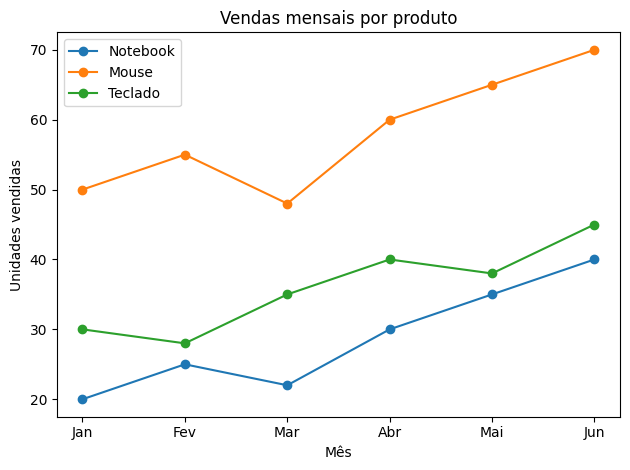

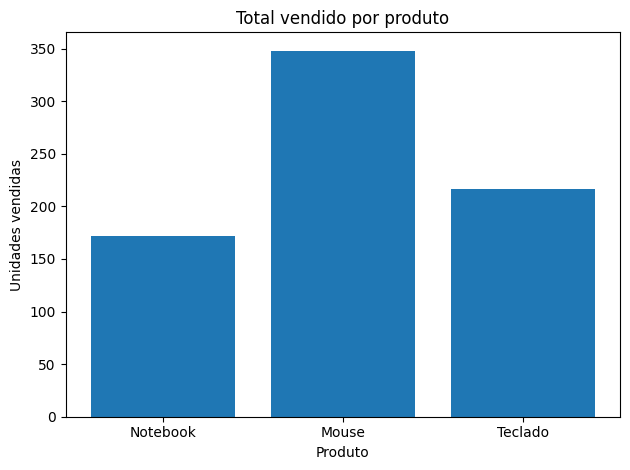

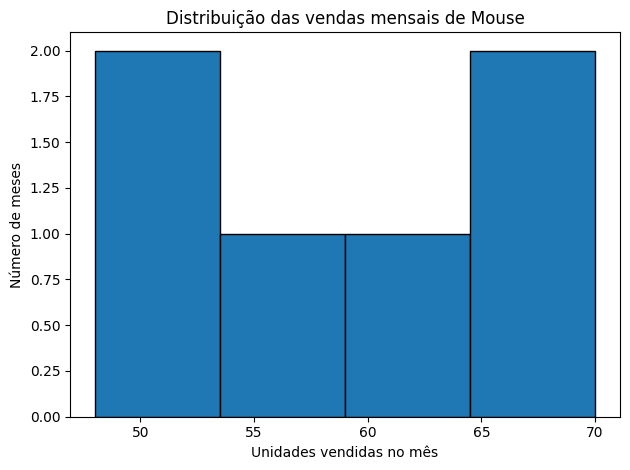

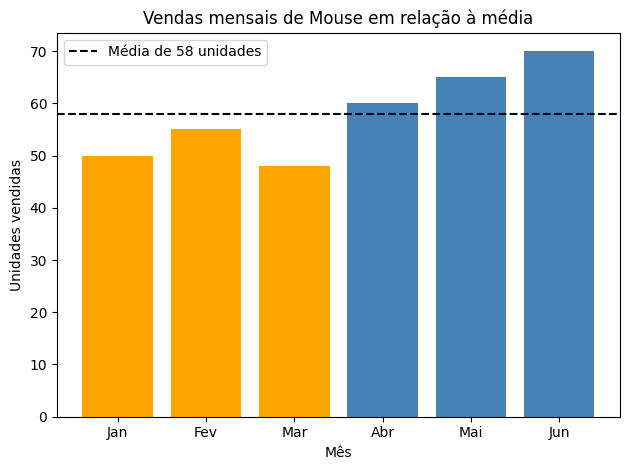

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45],
}

df = pd.DataFrame(dados)
produtos = ["Notebook", "Mouse", "Teclado"]


print("Primeiras linhas")
print(df.head())
print("\nDimensões (linhas, colunas)", df.shape)
print("\nEstatísticas descritivas")
print(df.describe())


print("\nIndicadores por produto")
for produto in produtos:
    vendas = df[produto].to_numpy()
    print(f"{produto} | Média {np.mean(vendas):.2f} | "
          f"Máximo {np.max(vendas)} | Mínimo {np.min(vendas)}")


plt.figure()
for produto in produtos:
    plt.plot(df["Mes"], df[produto], marker="o", label=produto)

plt.title("Vendas mensais por produto")
plt.xlabel("Mês")
plt.ylabel("Unidades vendidas")
plt.legend()
plt.tight_layout()


totais = df[produtos].sum()

plt.figure()
plt.bar(totais.index, totais.values)
plt.title("Total vendido por produto")
plt.xlabel("Produto")
plt.ylabel("Unidades vendidas")
plt.tight_layout()


plt.figure()
plt.hist(df["Mouse"], bins=4, edgecolor="black")
plt.title("Distribuição das vendas mensais de Mouse")
plt.xlabel("Unidades vendidas no mês")
plt.ylabel("Número de meses")
plt.tight_layout()


lider = totais.idxmax()
print(f"\nProduto mais vendido no período — {lider} ({totais[lider]} unidades)")

for produto in produtos:
    linha = df[produto].idxmax()
    mes = df.loc[linha, "Mes"]
    quantidade = df.loc[linha, produto]
    print(f"Pico de {produto} — {mes} ({quantidade} unidades)")


media_mouse = np.mean(df["Mouse"].to_numpy())
cores = ["orange" if venda < media_mouse else "steelblue" for venda in df["Mouse"]]

plt.figure()
plt.bar(df["Mes"], df["Mouse"], color=cores)
plt.axhline(media_mouse, color="black", linestyle="--",
            label=f"Média de {media_mouse:.0f} unidades")
plt.title("Vendas mensais de Mouse em relação à média")
plt.xlabel("Mês")
plt.ylabel("Unidades vendidas")
plt.legend()
plt.tight_layout()

plt.show()
